# 10 · Pitt Image Ads: ¿se separan los anuncios positivos de los negativos? (CLIP congelado + sonda)

**Pregunta 1 · Separabilidad.** Con el codificador de imagen de CLIP ViT-B/16 **congelado** (sin ajustar) y una **sonda lineal** (regresión logística), ¿se distinguen los anuncios de valencia positiva de los de valencia negativa?

**Pregunta 2 · Anotaciones.** Si se separan, ¿mejora la separación al agregar **solo anotaciones humanas** de Pitt? **No se usa ningún texto impreso en la imagen** (sin OCR).

| Anotación | Archivo | Qué contiene | Cómo entra al modelo |
|---|---|---|---|
| Tema | `Topics.json` | Tema elegido por cada anotador (38 temas, κ ≈ 0,71) | Proporción de votos por tema (39 columnas) |
| QA | `QA_Action.json`, `QA_Reason.json`, `QA_Combined…` | "I should… because…" escrito por los anotadores | Codificador de texto de CLIP (promedio de frases) |
| Símbolos | `Symbols.json` | Qué representa una región ("danger", "freedom"…), escrito por anotadores | Codificador de texto de CLIP + indicador |

Los **sentimientos** no se usan como entrada: de ahí sale la etiqueta.

**Etiquetas** (las mismas reglas que el notebook 09): cada sentimiento tiene una valencia, cada anotador vota la valencia con más marcas y el anuncio recibe la de la **mayoría estricta** (> 50 %). Aquí solo se usan los anuncios **Positivos** y **Negativos**: todos los negativos (265) y 2.000 positivos al azar, los mismos del notebook 09 (se reutilizan sus imágenes).

**Evaluación:** validación cruzada estratificada 5 × 5 (5 pliegues, 5 repeticiones). `C` se elige **dentro** de cada pliegue. La métrica principal es el **ROC-AUC**: no depende del desbalance ni del umbral, y responde directamente "¿qué tan bien se separan?" (0,5 = azar · 0,7 aceptable · 0,8 buena · 0,9 excelente).

**Advertencia:** las anotaciones son interpretaciones humanas y no existen para un anuncio nuevo. Indican cuánto aporta *entender* el anuncio, no lo que lograría un sistema automático. Además, el QA puede venir de las mismas personas que marcaron los sentimientos.

## 1. Entorno y rutas

In [1]:
import glob
import io
import json
import os
import re
import subprocess
import sys
import time
import urllib.request
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Desde VS Code (extensión de Colab): use antes "Colab: Mount Google Drive to Server..."
    if not os.path.isdir('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/publicity_analysis'
    PITT_DIR = os.path.join(DRIVE_ROOT, 'pitt')
    IMG_DIR = '/content/work/pitt_256'
    PITT_CACHE_ZIP = os.path.join(PITT_DIR, 'etapa2_256.zip')   # creado por el notebook 09 (si existe)
    OUT = os.path.join(DRIVE_ROOT, 'resultados', 'pitt_binario')
else:
    PITT_DIR = 'pitt'                                            # votos incluidos en el repositorio
    IMG_DIR = os.path.expanduser('~/datasets/pitt_256')          # fuera del repositorio
    PITT_CACHE_ZIP = None
    OUT = os.path.join('resultados', 'pitt_binario')
VOTOS_IMG = os.path.join(PITT_DIR, 'votos', 'image')
for d in (IMG_DIR, OUT):
    os.makedirs(d, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
CLIP_NAME = 'openai/clip-vit-base-patch16'
URL_VOTOS = 'https://people.cs.pitt.edu/~kovashka/ads/annotations_images.zip'
URL_IMG = 'https://people.cs.pitt.edu/~mzhang/image_ads/'
UA = {'User-Agent': 'Mozilla/5.0 (research dataset downloader)'}
SEED = 0
N_POS = 2000           # positivos al azar (los negativos se usan todos)
N_SPLITS, N_REPEATS = 5, 5
CV = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
C_GRID = {'logisticregression__C': [1e-3, 1e-2, 1e-1, 1.0]}
pd.set_option('display.float_format', '{:.3f}'.format)
print('Dispositivo:', DEVICE, '· resultados en', OUT)

Dispositivo: mps · resultados en resultados/pitt_binario


## 2. Etiquetas: positivo vs negativo

Asignación de los 30 sentimientos de Pitt a una valencia (igual que el notebook 09). Los anuncios Neutros (sin sentimientos con valencia) y los sin mayoría quedan fuera.

In [2]:
def fetch(url, timeout=60, retries=3):
    for k in range(retries):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=timeout) as r:
                return r.read()
        except Exception:
            if k == retries - 1:
                raise
            time.sleep(1.5 * (k + 1))


if not os.path.exists(os.path.join(VOTOS_IMG, 'Sentiments.json')):
    with zipfile.ZipFile(io.BytesIO(fetch(URL_VOTOS))) as z:
        z.extractall(os.path.join(PITT_DIR, 'votos'))
load = lambda f: json.load(open(os.path.join(VOTOS_IMG, f + '.json')))

SENT_VALENCIA = {
    **dict.fromkeys(['active', 'amazed', 'amused', 'calm', 'cheerful', 'confident', 'eager', 'grateful',
                     'inspired', 'loving', 'persuaded', 'proud'], 'Positive'),
    **dict.fromkeys(['afraid', 'alarmed', 'angry', 'disturbed', 'jealous', 'pessimistic', 'sad'], 'Negative'),
    **dict.fromkeys(['alert', 'conscious', 'creative', 'educated', 'emotional', 'empathetic', 'fashionable',
                     'feminine', 'manly', 'thrifty', 'youthful'], 'Neutral'),
}


def parse_list(path, enc):
    out = {}
    for line in open(path, encoding=enc):
        m = re.match(r'\s*(\d+)[.,]?\s+"([^"]+)"(?:.*ABBREVIATION:\s*"([^"]+)")?', line)
        if m:
            out[m.group(1)] = m.group(3) or m.group(2).lower()
    return out


SENT_NAMES = parse_list(os.path.join(VOTOS_IMG, 'Sentiments_List.txt'), 'latin-1')
TOPIC_NAMES = parse_list(os.path.join(VOTOS_IMG, 'Topics_List.txt'), 'utf-16')
assert set(SENT_NAMES.values()) == set(SENT_VALENCIA)


def valencia_anotador(ids):
    v = Counter(SENT_VALENCIA.get(SENT_NAMES.get(str(i)), 'Neutral') for i in ids)
    return 'Positive' if v['Positive'] > v['Negative'] else 'Negative' if v['Negative'] > v['Positive'] else 'Neutral'


filas = []
for key, vs in load('Sentiments').items():
    if len(vs) < 2:
        continue
    u = [valencia_anotador(v) for v in vs]
    top, n_top = Counter(u).most_common(1)[0]
    if n_top / len(u) > 0.5 and top != 'Neutral':
        filas.append({'key': key, 'valencia': top, 'acuerdo': n_top / len(u), 'n_anotadores': len(u)})
pitt = pd.DataFrame(filas)
print(pitt['valencia'].value_counts().to_dict())

# Misma muestra de positivos que el notebook 09 (mismo orden y semilla)
neg = pitt[pitt['valencia'] == 'Negative']
pos = pitt[pitt['valencia'] == 'Positive'].sample(n=N_POS, random_state=SEED)
data = pd.concat([pos, neg]).sort_values('key').reset_index(drop=True)
data['y'] = (data['valencia'] == 'Negative').astype(int)     # 1 = Negativo (clase minoritaria)
print(f'Muestra: {len(data)} anuncios · {data["y"].sum()} negativos ({data["y"].mean():.1%})')
display(pd.crosstab(data['valencia'], data['acuerdo'].round(2), margins=True))

{'Positive': 15729, 'Negative': 265}
Muestra: 2265 anuncios · 265 negativos (11.7%)


acuerdo,0.600,0.670,0.800,1.000,All
valencia,,,,,
Negative,20,229,3,13,265
Positive,166,1185,146,503,2000
All,186,1414,149,516,2265


## 3. Imágenes (256 px de lado menor, sin recortar)

In [3]:
local_name = lambda key: key.replace('/', '_').rsplit('.', 1)[0] + '.jpg'
if PITT_CACHE_ZIP and os.path.exists(PITT_CACHE_ZIP):
    with zipfile.ZipFile(PITT_CACHE_ZIP) as z:
        z.extractall(IMG_DIR)


def bajar(key):
    dst = os.path.join(IMG_DIR, local_name(key))
    if os.path.exists(dst):
        return 'existe'
    try:
        im = Image.open(io.BytesIO(fetch(URL_IMG + key))).convert('RGB')
        s = 256 / min(im.size)
        if s < 1:
            im = im.resize((round(im.width * s), round(im.height * s)), Image.BICUBIC)
        im.save(dst + '.part', 'JPEG', quality=92)
        os.replace(dst + '.part', dst)
        return 'nueva'
    except Exception:
        return 'error'


t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    estados = Counter(ex.map(bajar, data['key']))
print(dict(estados), f'· {time.time() - t0:.0f}s')
data['path'] = data['key'].map(lambda k: os.path.join(IMG_DIR, local_name(k)))
data = data[data['path'].map(os.path.exists)].reset_index(drop=True)
y = data['y'].to_numpy()
print(f'{len(data)} anuncios con imagen · {y.sum()} negativos')

{'existe': 2265} · 0s
2265 anuncios con imagen · 265 negativos


## 4. Embeddings de imagen con CLIP congelado

La imagen completa se lleva a 224 × 224 (sin recortar bordes, igual que en el notebook 09) y se toma el embedding de 512 dimensiones del codificador de imagen. Se guardan en `OUT` y se reutilizan.

In [4]:
from transformers import CLIPTextModelWithProjection, CLIPTokenizer, CLIPVisionModelWithProjection
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

vis = CLIPVisionModelWithProjection.from_pretrained(CLIP_NAME).to(DEVICE).eval()
txt = CLIPTextModelWithProjection.from_pretrained(CLIP_NAME).to(DEVICE).eval()
tok = CLIPTokenizer.from_pretrained(CLIP_NAME)
tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                T.Normalize([0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711])])


@torch.no_grad()
def image_emb(paths, batch=64):
    out = []
    for i in range(0, len(paths), batch):
        x = torch.stack([tf(Image.open(p).convert('RGB')) for p in paths[i:i + batch]]).to(DEVICE)
        out.append(F.normalize(vis(pixel_values=x).image_embeds.float(), dim=-1).cpu())
    return torch.cat(out).numpy()


@torch.no_grad()
def text_emb(texts, batch=256):
    out = []
    for i in range(0, len(texts), batch):
        t = tok(texts[i:i + batch], padding=True, truncation=True, max_length=77, return_tensors='pt').to(DEVICE)
        out.append(F.normalize(txt(**t).text_embeds.float(), dim=-1).cpu())
    return torch.cat(out).numpy()


emb_path = os.path.join(OUT, 'clip_img_emb.npz')
if os.path.exists(emb_path) and list(np.load(emb_path)['key']) == data['key'].tolist():
    X_img = np.load(emb_path)['X']
else:
    t0 = time.time()
    X_img = image_emb(data['path'].tolist())
    np.savez(emb_path, X=X_img, key=data['key'].to_numpy(dtype=str))
    print(f'{len(X_img)} embeddings en {time.time() - t0:.0f}s')
print('X_img', X_img.shape)

/private/tmp/claude-501/-Users-miguelcarrascoudp-Documents-GitHub-publicity-analysis/9d4b2e34-c6c2-43a1-bb9e-97865f2c2b02/scratchpad/venv_torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1120 18:44:07.597000 88416 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 52448.47it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 58004.77it/s]


X_img (2265, 512)


## 5. ¿Se separan? Sonda lineal sobre CLIP congelado

Para cada pliegue: regresión logística con pesos de clase balanceados y `C` elegido con una validación cruzada interna (ROC-AUC). Se guardan las probabilidades **fuera de pliegue** (cada anuncio se predice con un modelo que no lo vio).

Referencia sin entrenamiento: **CLIP zero-shot** comparando la imagen con frases como *"an advertisement that makes people feel happy"* vs *"… feel sad, afraid or disturbed"*.

In [5]:
def sonda_cv(X, y, cv=CV):
    """Probabilidad de Negativo fuera de pliegue, una columna por repetición."""
    P = np.zeros((len(y), N_REPEATS))
    for k, (tr, te) in enumerate(cv.split(X, y)):
        pipe = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=5000))
        gs = GridSearchCV(pipe, C_GRID, scoring='roc_auc',
                          cv=StratifiedKFold(3, shuffle=True, random_state=k)).fit(X[tr], y[tr])
        P[te, k // N_SPLITS] = gs.predict_proba(X[te])[:, 1]
    return P


def metricas(y, P, nombre):
    # media sobre repeticiones; umbral 0,5 (los pesos balanceados ya compensan el desbalance)
    r = {'entrada': nombre}
    for m, f in [('roc_auc', roc_auc_score), ('pr_auc', average_precision_score)]:
        r[m] = np.mean([f(y, P[:, j]) for j in range(P.shape[1])])
    pred = P >= 0.5
    r['balanced_acc'] = np.mean([balanced_accuracy_score(y, pred[:, j]) for j in range(P.shape[1])])
    r['sensibilidad_neg'] = np.mean([pred[y == 1, j].mean() for j in range(P.shape[1])])
    r['especificidad_pos'] = np.mean([1 - pred[y == 0, j].mean() for j in range(P.shape[1])])
    r['f1_neg'] = np.mean([f1_score(y, pred[:, j]) for j in range(P.shape[1])])
    return r


def auc_rep(y, P):
    # AUC promedio sobre repeticiones (la misma cantidad que se reporta como estimación puntual)
    P = P.reshape(len(y), -1)
    return np.mean([roc_auc_score(y, P[:, j]) for j in range(P.shape[1])])


def auc_ci(y, P, n=1000, seed=0):
    # IC95% por bootstrap de anuncios (se remuestrean los mismos anuncios en todas las repeticiones)
    g = np.random.default_rng(seed)
    v = [auc_rep(y[i], P[i]) for i in (g.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(v, [2.5, 97.5])


t0 = time.time()
P_img = sonda_cv(X_img, y)
res_img = metricas(y, P_img, 'imagen (CLIP congelado)')
lo, hi = auc_ci(y, P_img)
res_img['roc_auc_ic95'] = f'[{lo:.3f}, {hi:.3f}]'

# Zero-shot
POS_TXT = ['an advertisement that makes people feel happy.', 'a cheerful, inspiring advertisement.',
           'an ad that makes people feel proud and confident.', 'a fun and amusing advertisement.']
NEG_TXT = ['an advertisement that makes people feel sad.', 'a disturbing, shocking advertisement.',
           'an ad that makes people feel afraid or alarmed.', 'an advertisement that makes people angry.']
w = [F.normalize(torch.tensor(text_emb(t)).mean(0), dim=0).numpy() for t in (POS_TXT, NEG_TXT)]
s_zs = X_img @ (w[1] - w[0])
res_zs = {'entrada': 'CLIP zero-shot (sin entrenar)', 'roc_auc': roc_auc_score(y, s_zs),
          'pr_auc': average_precision_score(y, s_zs)}
lo, hi = auc_ci(y, s_zs)
res_zs['roc_auc_ic95'] = f'[{lo:.3f}, {hi:.3f}]'
sep = pd.DataFrame([res_zs, res_img]).set_index('entrada')
display(sep)
print(f'({time.time() - t0:.0f}s) · PR-AUC de azar = proporción de negativos = {y.mean():.3f}')

,roc_auc,pr_auc,roc_auc_ic95,balanced_acc,sensibilidad_neg,especificidad_pos,f1_neg
entrada,,,,,,,
CLIP zero-shot (sin entrenar),0.848,0.602,"[0.819, 0.873]",NaN,NaN,NaN,NaN
imagen (CLIP congelado),0.955,0.800,"[0.942, 0.966]",0.885,0.838,0.932,0.713


(6s) · PR-AUC de azar = proporción de negativos = 0.117


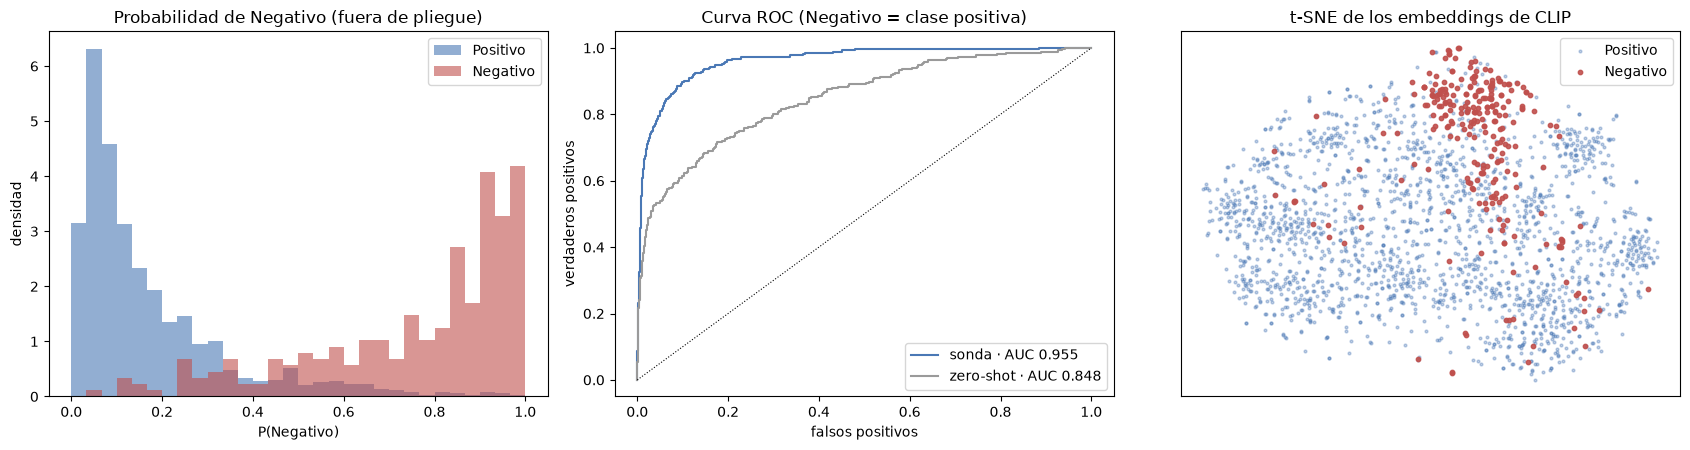

In [6]:
from sklearn.manifold import TSNE

p = P_img.mean(1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
for c, col, lab in [(0, '#4a78b5', 'Positivo'), (1, '#c0504d', 'Negativo')]:
    ax.hist(p[y == c], bins=30, range=(0, 1), alpha=0.6, density=True, color=col, label=lab)
ax.set(title='Probabilidad de Negativo (fuera de pliegue)', xlabel='P(Negativo)', ylabel='densidad'); ax.legend()

ax = axes[1]
for s, lab, col in [(p, f'sonda · AUC {res_img["roc_auc"]:.3f}', '#4a78b5'),
                    (s_zs, f'zero-shot · AUC {res_zs["roc_auc"]:.3f}', '#9a9a9a')]:
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, label=lab, color=col)
ax.plot([0, 1], [0, 1], ls=':', color='black', lw=0.8)
ax.set(title='Curva ROC (Negativo = clase positiva)', xlabel='falsos positivos', ylabel='verdaderos positivos'); ax.legend()

ax = axes[2]
Z = TSNE(n_components=2, random_state=SEED, init='pca', perplexity=30).fit_transform(X_img)
ax.scatter(*Z[y == 0].T, s=4, c='#4a78b5', alpha=0.35, label='Positivo')
ax.scatter(*Z[y == 1].T, s=10, c='#c0504d', alpha=0.9, label='Negativo')
ax.set(title='t-SNE de los embeddings de CLIP', xticks=[], yticks=[]); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'separabilidad_imagen.png'), dpi=150); plt.show()

### 5b. ¿Dónde se equivoca? Separabilidad según el acuerdo entre anotadores y el tema

Si el AUC es mayor en los anuncios donde los anotadores coinciden más, parte del error viene del **ruido de las etiquetas** y no del modelo.

In [7]:
TOPICS = load('Topics')


def tema_mayoritario(key):
    v = [str(t).strip() for t in TOPICS.get(key, [])]
    v = [TOPIC_NAMES.get(t, 'other') if t.isdigit() else 'other' for t in v]
    return Counter(v).most_common(1)[0][0] if v else 'other'


data['tema'] = data['key'].map(tema_mayoritario)
data['p_neg'] = p
rows = []
for a, g in data.groupby(data['acuerdo'].round(2)):
    if g['y'].nunique() == 2:
        rows.append({'acuerdo': a, 'anuncios': len(g), 'negativos': int(g['y'].sum()),
                     'roc_auc': roc_auc_score(g['y'], g['p_neg'])})
display(pd.DataFrame(rows).set_index('acuerdo'))

t = data.groupby('tema').agg(anuncios=('y', 'size'), negativos=('y', 'sum'), p_neg_media=('p_neg', 'mean'))
t['pct_neg'] = t['negativos'] / t['anuncios']
display(t[t['negativos'] >= 5].sort_values('negativos', ascending=False).head(12))

,anuncios,negativos,roc_auc
acuerdo,,,
0.600,186,20,0.950
0.670,1414,229,0.958
0.800,149,3,0.963
1.000,516,13,0.971


,anuncios,negativos,p_neg_media,pct_neg
tema,,,,
smoking_alcohol_abuse,56,47,0.825,0.839
safety,49,43,0.795,0.878
domestic_violence,25,25,0.929,1.000
animal_right,28,22,0.782,0.786
environment,27,15,0.652,0.556
human_right,18,14,0.768,0.778
healthcare,39,13,0.487,0.333
self_esteem,12,12,0.876,1.000
media,54,11,0.324,0.204


## 6. ¿Mejora la separación con anotaciones? (sin texto de la imagen)

Cada bloque se estandariza y se concatena al embedding de imagen. Los anuncios sin una anotación reciben ceros y un indicador de "falta".

**Δ AUC** compara cada combinación con *solo imagen* sobre las **mismas** probabilidades fuera de pliegue (mismos pliegues), con IC95 % por *bootstrap* pareado. Si el intervalo no incluye 0, la anotación mejora la separación.

In [8]:
# Tema: proporción de votos por tema (39 columnas, incluye "other")
temas = sorted(set(TOPIC_NAMES.values()) | {'other'})
ti = {t: i for i, t in enumerate(temas)}
X_tema = np.zeros((len(data), len(temas)), np.float32)
for j, k in enumerate(data['key']):
    v = [str(t).strip() for t in TOPICS.get(k, [])]
    for t in v:
        X_tema[j, ti[TOPIC_NAMES.get(t, 'other') if t.isdigit() else 'other']] += 1 / len(v)


def emb_frases(listas):
    # promedio de embeddings de texto por anuncio; sin frases → ceros, más una columna indicadora
    frases = [s for l in listas for s in l]
    E_ = text_emb(frases) if frases else None
    out, i = np.zeros((len(listas), E_.shape[1] + 1), np.float32), 0
    for j, l in enumerate(listas):
        if l:
            out[j, :-1] = E_[i:i + len(l)].mean(0); out[j, -1] = 1
            i += len(l)
    return out


QA = {}
for f in ('QA_Action', 'QA_Reason', 'QA_Combined_Action_Reason'):
    for k, v in load(f).items():
        QA.setdefault(k, []).extend(s.strip() for s in v if isinstance(s, str) and s.strip())
SYM = {k: [str(r[4]).strip() for r in v if len(r) >= 5 and str(r[4]).strip()] for k, v in load('Symbols').items()}

t0 = time.time()
X_qa = emb_frases([QA.get(k, []) for k in data['key']])
X_sym = emb_frases([SYM.get(k, []) for k in data['key']])
cob = pd.DataFrame({'tema': X_tema.sum(1) > 0, 'QA': X_qa[:, -1] > 0, 'símbolos': X_sym[:, -1] > 0})
print(f'Texto codificado en {time.time() - t0:.0f}s · cobertura:')
display(cob.groupby(y).mean().rename(index={0: 'Positivo', 1: 'Negativo'}))

Texto codificado en 10s · cobertura:


,tema,QA,símbolos
Positivo,1.000,0.991,0.308
Negativo,1.000,0.981,0.736


In [9]:
ENTRADAS = {
    'imagen + tema': np.c_[X_img, X_tema],
    'imagen + QA': np.c_[X_img, X_qa],
    'imagen + símbolos': np.c_[X_img, X_sym],
    'imagen + tema + QA + símbolos': np.c_[X_img, X_tema, X_qa, X_sym],
    'solo anotaciones (tema + QA + símbolos)': np.c_[X_tema, X_qa, X_sym],
}


def delta_auc_ci(y, P1, P0, n=1000, seed=0):
    # bootstrap pareado: los mismos anuncios remuestreados para ambas entradas
    g = np.random.default_rng(seed)
    d = [auc_rep(y[i], P1[i]) - auc_rep(y[i], P0[i]) for i in (g.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(d, [2.5, 97.5])


filas, PROBS = [dict(res_img)], {'imagen (CLIP congelado)': P_img}
for nombre, X in ENTRADAS.items():
    t0 = time.time()
    P = sonda_cv(X, y)
    PROBS[nombre] = P
    r = metricas(y, P, nombre)
    lo, hi = auc_ci(y, P)
    dlo, dhi = delta_auc_ci(y, P, P_img)
    r.update(roc_auc_ic95=f'[{lo:.3f}, {hi:.3f}]', delta_auc=r['roc_auc'] - res_img['roc_auc'],
             delta_auc_ic95=f'[{dlo:+.3f}, {dhi:+.3f}]')
    filas.append(r)
    print(f'{nombre}: AUC {r["roc_auc"]:.3f} · Δ {r["delta_auc"]:+.3f} [{dlo:+.3f}, {dhi:+.3f}] · {time.time() - t0:.0f}s', flush=True)
res = pd.concat([pd.DataFrame([res_zs]), pd.DataFrame(filas)]).set_index('entrada')
res.to_csv(os.path.join(OUT, 'separabilidad_resumen.csv'))
display(res)

imagen + tema: AUC 0.962 · Δ +0.007 [+0.003, +0.011] · 13s
imagen + QA: AUC 0.966 · Δ +0.011 [+0.004, +0.019] · 14s
imagen + símbolos: AUC 0.967 · Δ +0.012 [+0.004, +0.020] · 14s
imagen + tema + QA + símbolos: AUC 0.969 · Δ +0.014 [+0.004, +0.025] · 15s
solo anotaciones (tema + QA + símbolos): AUC 0.960 · Δ +0.005 [-0.009, +0.018] · 14s


,roc_auc,pr_auc,roc_auc_ic95,balanced_acc,sensibilidad_neg,especificidad_pos,f1_neg,delta_auc,delta_auc_ic95
entrada,,,,,,,,,
CLIP zero-shot (sin entrenar),0.848,0.602,"[0.819, 0.873]",NaN,NaN,NaN,NaN,NaN,NaN
imagen (CLIP congelado),0.955,0.800,"[0.942, 0.966]",0.885,0.838,0.932,0.713,NaN,NaN
imagen + tema,0.962,0.833,"[0.949, 0.973]",0.899,0.854,0.945,0.752,0.007,"[+0.003, +0.011]"
imagen + QA,0.966,0.845,"[0.955, 0.975]",0.904,0.848,0.961,0.791,0.011,"[+0.004, +0.019]"
imagen + símbolos,0.967,0.867,"[0.954, 0.977]",0.892,0.821,0.964,0.784,0.012,"[+0.004, +0.020]"
imagen + tema + QA + símbolos,0.969,0.876,"[0.957, 0.980]",0.910,0.849,0.970,0.818,0.014,"[+0.004, +0.025]"
solo anotaciones (tema + QA + símbolos),0.960,0.853,"[0.945, 0.974]",0.903,0.840,0.966,0.801,0.005,"[-0.009, +0.018]"


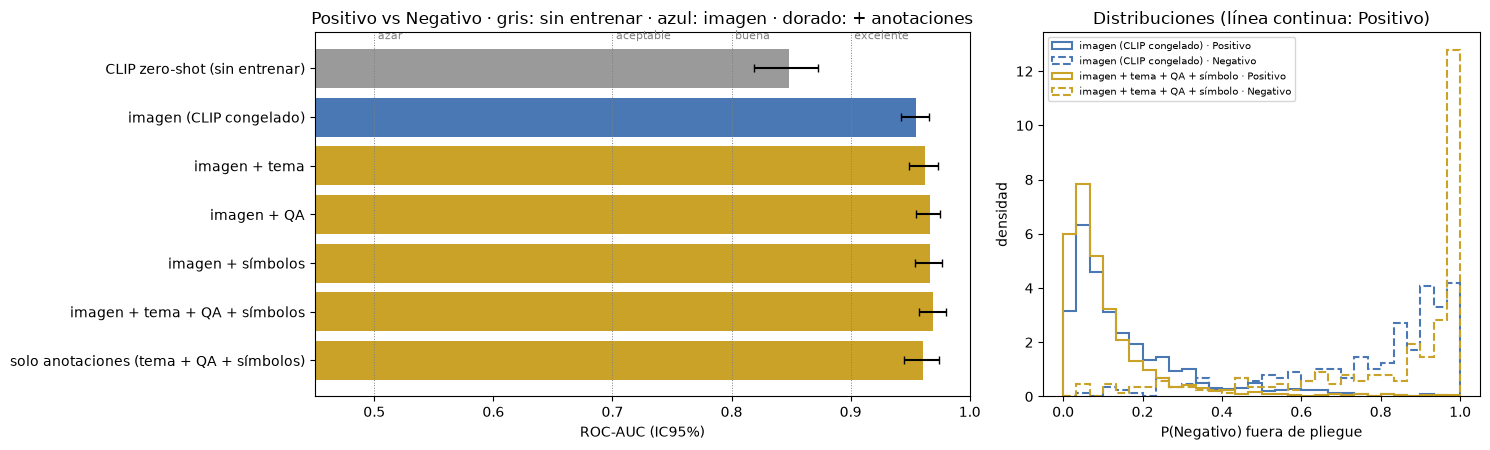

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [3, 2]})
ax = axes[0]
orden = list(res.index)
ci = res['roc_auc_ic95'].str.strip('[]').str.split(', ', expand=True).astype(float)
col = ['#9a9a9a', '#4a78b5'] + ['#c9a227'] * (len(orden) - 2)
ax.barh(range(len(orden)), res['roc_auc'], color=col)
ax.errorbar(res['roc_auc'], range(len(orden)), xerr=[res['roc_auc'] - ci[0], ci[1] - res['roc_auc']],
            fmt='none', ecolor='black', capsize=3)
for x, lab in [(0.5, 'azar'), (0.7, 'aceptable'), (0.8, 'buena'), (0.9, 'excelente')]:
    ax.axvline(x, color='grey', ls=':', lw=0.7); ax.text(x + 0.003, -0.6, lab, fontsize=8, color='grey')
ax.set_yticks(range(len(orden)), orden); ax.invert_yaxis()
ax.set(xlim=(0.45, 1.0), xlabel='ROC-AUC (IC95%)', title='Positivo vs Negativo · gris: sin entrenar · azul: imagen · dorado: + anotaciones')

ax = axes[1]
best = res.drop(index=['CLIP zero-shot (sin entrenar)'])['roc_auc'].idxmax()
for nombre, colr in [('imagen (CLIP congelado)', '#4a78b5'), (best, '#c9a227')]:
    pr = PROBS[nombre].mean(1)
    for c, ls in [(0, '-'), (1, '--')]:
        ax.hist(pr[y == c], bins=30, range=(0, 1), histtype='step', density=True, color=colr, ls=ls, lw=1.5,
                label=f'{nombre[:28]} · {"Positivo" if c == 0 else "Negativo"}')
ax.set(xlabel='P(Negativo) fuera de pliegue', ylabel='densidad', title='Distribuciones (línea continua: Positivo)')
ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'separabilidad_anotaciones.png'), dpi=150); plt.show()

## 7. Cómo leer los resultados

- **¿Se separan?** Mire el ROC-AUC de *imagen (CLIP congelado)*: ≥ 0,8 es una separación buena; entre 0,7 y 0,8, aceptable. La **sensibilidad** dice qué proporción de los negativos se detecta y la **especificidad** qué proporción de los positivos se reconoce como tal (umbral 0,5).
- **PR-AUC** es más exigente con la clase minoritaria: su valor de azar es la proporción de negativos (~12 %), no 0,5.
- **Δ AUC de las anotaciones:** si el IC95 % excluye 0, la anotación aporta información que la imagen sola no tiene. El **tema** suele ser decisivo: muchos negativos son campañas de bien público (seguridad, tabaco, violencia doméstica, derechos de los animales).
- **Solo anotaciones** muestra cuánto se separa sin mirar la imagen; si se acerca a *imagen + anotaciones*, la imagen agrega poco a lo que ya dicen las personas.
- Estas anotaciones **no existen para anuncios nuevos**: son un techo, no un sistema aplicable.

### 6b. Control: ¿los símbolos aportan por su contenido o porque *tenerlos* ya delata al negativo?

Pitt anotó símbolos en el 74 % de los negativos pero solo en el 31 % de los positivos. El indicador "tiene símbolos" (y el vector de ceros) puede separar por sí solo. Aquí se repite la comparación **solo con los anuncios que tienen símbolos**, donde esa pista no existe, y se agrega una entrada con **solo el indicador**.

In [11]:
con_sym = X_sym[:, -1] > 0
ys = y[con_sym]
print(f'Anuncios con símbolos: {con_sym.sum()} · negativos {ys.sum()} ({ys.mean():.1%})')
P0 = sonda_cv(X_img[con_sym], ys)
P1 = sonda_cv(np.c_[X_img, X_sym][con_sym], ys)
dlo, dhi = delta_auc_ci(ys, P1, P0)
P_ind = sonda_cv(X_sym[:, -1:], y)
filas_ctrl = [
    {'conjunto': 'todos', 'entrada': 'solo indicador "tiene símbolos"', 'roc_auc': auc_rep(y, P_ind)},
    {'conjunto': 'con símbolos', 'entrada': 'imagen', 'roc_auc': auc_rep(ys, P0)},
    {'conjunto': 'con símbolos', 'entrada': 'imagen + símbolos', 'roc_auc': auc_rep(ys, P1),
     'delta_auc': auc_rep(ys, P1) - auc_rep(ys, P0), 'delta_auc_ic95': f'[{dlo:+.3f}, {dhi:+.3f}]'},
]
display(pd.DataFrame(filas_ctrl).set_index(['conjunto', 'entrada']))

Anuncios con símbolos: 812 · negativos 195 (24.0%)


roc_auc  delta_auc  \
conjunto     entrada                                               
todos        solo indicador "tiene símbolos"    0.695        NaN   
con símbolos imagen                             0.941        NaN   
             imagen + símbolos                  0.962      0.021   

                                                delta_auc_ic95  
conjunto     entrada                                            
todos        solo indicador "tiene símbolos"               NaN  
con símbolos imagen                                        NaN  
             imagen + símbolos                [+0.007, +0.034]